In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
!ls -R '/content/drive/MyDrive/ai'

/content/drive/MyDrive/ai:
Directory.Build.targets  download-models.ps1  env.example  models  src

/content/drive/MyDrive/ai/models:
face_detection_yunet_2023mar.onnx    manifest.json
face_recognition_sface_2021dec.onnx

/content/drive/MyDrive/ai/src:
CityGym.AI  CityGym.AI.Cli

/content/drive/MyDrive/ai/src/CityGym.AI:
AssemblyInfo.cs  CityGym.AI.csproj  FeatureMath.cs  SFaceExtractor.cs
bin		 FaceEngine.cs	    obj

/content/drive/MyDrive/ai/src/CityGym.AI/bin:
Debug

/content/drive/MyDrive/ai/src/CityGym.AI/bin/Debug:
net8.0

/content/drive/MyDrive/ai/src/CityGym.AI/bin/Debug/net8.0:
CityGym.AI.deps.json  CityGym.AI.dll  CityGym.AI.pdb

/content/drive/MyDrive/ai/src/CityGym.AI/obj:
CityGym.AI.csproj.nuget.dgspec.json  Debug
CityGym.AI.csproj.nuget.g.props      project.assets.json
CityGym.AI.csproj.nuget.g.targets    project.nuget.cache

/content/drive/MyDrive/ai/src/CityGym.AI/obj/Debug:
net8.0

/content/drive/MyDrive/ai/src/CityGym.AI/obj/Debug/net8.0:
CityGym.AI.AssemblyInfo.cs
Cit

# Kiểm tra file

In [3]:
from pathlib import Path

root = Path("/content/drive/MyDrive/ai")

files = [
    root / "src/CityGym.AI/FaceEngine.cs",
    root / "src/CityGym.AI/SFaceExtractor.cs",
    root / "src/CityGym.AI/FeatureMath.cs",
    root / "src/CityGym.AI/CityGym.AI.csproj",
    root / "src/CityGym.AI.Cli/Program.cs",
    root / "src/CityGym.AI.Cli/CityGym.AI.Cli.csproj",
    root / "models/manifest.json",
]

for file in files:
    print(f"\nFILE: {file}")
    print(file.read_text(encoding="utf-8"))


FILE: /content/drive/MyDrive/ai/src/CityGym.AI/FaceEngine.cs
using OpenCvSharp;

namespace CityGym.AI;

public sealed record FaceFeature(string Model, string Pipeline, float[] Vector, float DetectionScore);
public sealed record GalleryEntry(string FaceInfoId, FaceFeature Feature);
public sealed record MatchResult(bool Found, string? FaceInfoId, double? Score);
public sealed class FaceInputException(string code, string message) : Exception(message)
{
    public string Code { get; } = code;
}

/// <summary>One CPU engine, serialized access to native models. No database or HTTP dependency.</summary>
public sealed class FaceEngine : IDisposable
{
    public const string Model = "opencv-sface-2021dec";
    public const string Pipeline = "yunet2023mar-similarity5-sface128-v1";
    private readonly FaceDetectorYN detector;
    private readonly SFaceExtractor recognizer;
    private readonly object gate = new();
    private bool disposed;

    public FaceEngine(string modelDirectory)
    {
  

In [4]:
from pathlib import Path
import json
import hashlib

root = Path("/content/drive/MyDrive/ai")
model_dir = root / "models"

models = [
    model_dir / "face_detection_yunet_2023mar.onnx",
    model_dir / "face_recognition_sface_2021dec.onnx",
]

for path in models:
    assert path.exists(), f"Missing model: {path}"

    size_mb = path.stat().st_size / (1024 * 1024)

    sha256 = hashlib.sha256(path.read_bytes()).hexdigest()

    print(path.name)
    print(f"Size: {size_mb:.3f} MB")
    print(f"SHA256: {sha256}")
    print()

manifest = model_dir / "manifest.json"

assert manifest.exists(), "Missing manifest.json"

print(manifest.read_text(encoding="utf-8"))

face_detection_yunet_2023mar.onnx
Size: 0.222 MB
SHA256: 8f2383e4dd3cfbb4553ea8718107fc0423210dc964f9f4280604804ed2552fa4

face_recognition_sface_2021dec.onnx
Size: 36.904 MB
SHA256: 0ba9fbfa01b5270c96627c4ef784da859931e02f04419c829e83484087c34e79

{
  "pipeline": "yunet2023mar-similarity5-sface128-v1",
  "models": [
    { "file": "face_detection_yunet_2023mar.onnx", "sha256": "8f2383e4dd3cfbb4553ea8718107fc0423210dc964f9f4280604804ed2552fa4", "url": "https://media.githubusercontent.com/media/opencv/opencv_zoo/main/models/face_detection_yunet/face_detection_yunet_2023mar.onnx" },
    { "file": "face_recognition_sface_2021dec.onnx", "sha256": "0ba9fbfa01b5270c96627c4ef784da859931e02f04419c829e83484087c34e79", "url": "https://media.githubusercontent.com/media/opencv/opencv_zoo/main/models/face_recognition_sface/face_recognition_sface_2021dec.onnx" }
  ]
}



# Cài thư viện

In [6]:
!wget -q https://packages.microsoft.com/config/debian/12/packages-microsoft-prod.deb -O /tmp/packages-microsoft-prod.deb
!dpkg -i /tmp/packages-microsoft-prod.deb
!apt-get update -qq
!apt-get install -y dotnet-sdk-8.0

Selecting previously unselected package packages-microsoft-prod.
(Reading database ... 122809 files and directories currently installed.)
Preparing to unpack .../packages-microsoft-prod.deb ...
Unpacking packages-microsoft-prod (1.1-debian12) ...
Setting up packages-microsoft-prod (1.1-debian12) ...
W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
The following additional packages will be installed:
  aspnetcore-runtime-8.0 aspnetcore-targeting-pack-8.0 dotnet-apphost-pack-8.0
  dotnet-host dotnet-hostfxr-8.0 dotnet-runtime-8.0 dotnet-runtime-deps-8.0
  dotnet-targeting-pack-8.0 netstandard-targeting-pack-2.1
The following NEW packages will be installed:
  aspnetcore-runtime-8.0 aspnetcore-targeting-pack-8.0 dotnet-apphost-pack-8.0
  dotnet-host dotnet-

In [7]:
import platform
import subprocess

print("OS:", platform.system())
print("Machine:", platform.machine())

result = subprocess.run(
    ["dotnet", "--info"],
    capture_output=True,
    text=True
)

print(result.stdout)

if result.stderr:
    print("STDERR:")
    print(result.stderr)

print("Return code:", result.returncode)

OS: Linux
Machine: x86_64
.NET SDK:
 Version:           8.0.425
 Commit:            4a98f641c7
 Workload version:  8.0.400-manifests.ac071bc2
 MSBuild version:   17.11.48+02bf66295

Runtime Environment:
 OS Name:     ubuntu
 OS Version:  24.04
 OS Platform: Linux
 RID:         linux-x64
 Base Path:   /usr/share/dotnet/sdk/8.0.425/

.NET workloads installed:
Configured to use loose manifests when installing new manifests.
There are no installed workloads to display.

Host:
  Version:      8.0.31
  Architecture: x64
  Commit:       1219a42122

.NET SDKs installed:
  8.0.425 [/usr/share/dotnet/sdk]

.NET runtimes installed:
  Microsoft.AspNetCore.App 8.0.31 [/usr/share/dotnet/shared/Microsoft.AspNetCore.App]
  Microsoft.NETCore.App 8.0.31 [/usr/share/dotnet/shared/Microsoft.NETCore.App]

Other architectures found:
  None

Environment variables:
  Not set

global.json file:
  Not found

Learn more:
  https://aka.ms/dotnet/info

Download .NET:
  https://aka.ms/dotnet/download

Return code: 

# Build


In [8]:
import subprocess

project = "/content/drive/MyDrive/ai/src/CityGym.AI/CityGym.AI.csproj"

result = subprocess.run(
    [
        "dotnet",
        "build",
        project,
        "--configuration",
        "Release"
    ],
    capture_output=True,
    text=True
)

print(result.stdout)

if result.stderr:
    print("STDERR:")
    print(result.stderr)

print("Return code:", result.returncode)


Welcome to .NET 8.0!
---------------------
SDK Version: 8.0.425

Telemetry
---------
The .NET tools collect usage data in order to help us improve your experience. It is collected by Microsoft and shared with the community. You can opt-out of telemetry by setting the DOTNET_CLI_TELEMETRY_OPTOUT environment variable to '1' or 'true' using your favorite shell.

Read more about .NET CLI Tools telemetry: https://aka.ms/dotnet-cli-telemetry

----------------
Installed an ASP.NET Core HTTPS development certificate.
To trust the certificate, view the instructions: https://aka.ms/dotnet-https-linux

----------------
Write your first app: https://aka.ms/dotnet-hello-world
Find out what's new: https://aka.ms/dotnet-whats-new
Explore documentation: https://aka.ms/dotnet-docs
Report issues and find source on GitHub: https://github.com/dotnet/core
Use 'dotnet --help' to see available commands or visit: https://aka.ms/dotnet-cli
----------------------------------------------------------------------

In [9]:
import subprocess

project = "/content/drive/MyDrive/ai/src/CityGym.AI.Cli/CityGym.AI.Cli.csproj"

result = subprocess.run(
    [
        "dotnet",
        "build",
        project,
        "--configuration",
        "Release"
    ],
    capture_output=True,
    text=True
)

print(result.stdout)

if result.stderr:
    print("STDERR:")
    print(result.stderr)

print("Return code:", result.returncode)

  Determining projects to restore...
  Restored /content/drive/MyDrive/ai/src/CityGym.AI.Cli/CityGym.AI.Cli.csproj (in 2.03 sec).
  1 of 2 projects are up-to-date for restore.
  CityGym.AI -> /content/drive/MyDrive/ai/src/CityGym.AI/bin/Release/net8.0/CityGym.AI.dll
  CityGym.AI.Cli -> /content/drive/MyDrive/ai/src/CityGym.AI.Cli/bin/Release/net8.0/CityGym.AI.Cli.dll

Build succeeded.
    0 Warning(s)
    0 Error(s)

Time Elapsed 00:00:11.29

Return code: 0


# Chạy FeatureMath self-test

In [10]:
import subprocess

cli_project = "/content/drive/MyDrive/ai/src/CityGym.AI.Cli/CityGym.AI.Cli.csproj"

result = subprocess.run(
    [
        "dotnet",
        "run",
        "--project",
        cli_project,
        "--configuration",
        "Release",
        "--",
        "self-test"
    ],
    capture_output=True,
    text=True
)

print("STDOUT:")
print(result.stdout)

if result.stderr:
    print("STDERR:")
    print(result.stderr)

print("Return code:", result.returncode)

STDOUT:
8 feature checks passed. Native inference requires smoke-test or extract.

Return code: 0


In [11]:
import subprocess

cli_project = "/content/drive/MyDrive/ai/src/CityGym.AI.Cli/CityGym.AI.Cli.csproj"
models = "/content/drive/MyDrive/ai/models"

result = subprocess.run(
    [
        "dotnet",
        "run",
        "--project",
        cli_project,
        "--configuration",
        "Release",
        "--",
        "smoke-test",
        models
    ],
    capture_output=True,
    text=True
)

print("STDOUT:")
print(result.stdout)

print("STDERR:")
print(result.stderr)

print("Return code:", result.returncode)

STDOUT:

STDERR:
{
  "code": "ENGINE_ERROR",
  "message": "The type initializer for \u0027OpenCvSharp.Internal.NativeMethods\u0027 threw an exception."
}

Return code: 1


In [12]:
import subprocess

packages = [
    "OpenCvSharp4.runtime.ubuntu.22.04-x64",
    "OpenCvSharp4.runtime.linux-x64",
    "OpenCvSharp4.official.runtime.linux-x64",
]

for package in packages:
    print(f"\nPACKAGE: {package}")

    result = subprocess.run(
        [
            "dotnet",
            "package",
            "search",
            package,
            "--take",
            "5"
        ],
        capture_output=True,
        text=True
    )

    print(result.stdout)

    if result.stderr:
        print("STDERR:")
        print(result.stderr)

    print("Return code:", result.returncode)


PACKAGE: OpenCvSharp4.runtime.ubuntu.22.04-x64
****************************************
Source: nuget.org (https://api.nuget.org/v3/index.json)
| Package ID       | Latest Version  | Owners        | Total Downloads |
| ---------------- | --------------- | ------------- | --------------- |
| Sdcb.OpenCvSharp | 4.11.0.35       | sdflysha      | 78,298          |
| 4.mini.runtime.u |                 |               |                 |
| buntu.22.04-x64  |                 |               |                 |
| ---------------- | --------------- | ------------- | --------------- |
| OpenVINO.runtime | 2026.4.0        | GuojinYan     | 11,365          |
| .ubuntu.22-x86_6 |                 |               |                 |
| 4                |                 |               |                 |
| ---------------- | --------------- | ------------- | --------------- |
| OpenCvSharp4.off | 4.13.0.20260308 | schimatk      | 4,912           |
| icial.runtime.ub |                 |              

In [13]:
from pathlib import Path
import shutil

csproj = Path(
    "/content/drive/MyDrive/ai/src/CityGym.AI/CityGym.AI.csproj"
)

backup = csproj.with_suffix(".csproj.backup")

if not backup.exists():
    shutil.copy2(csproj, backup)
    print("Backup created:", backup)
else:
    print("Backup already exists:", backup)

content = csproj.read_text(encoding="utf-8")

old_package = (
    '<PackageReference Include="OpenCvSharp4.runtime.win" '
    'Version="4.13.0.20260627" />'
)

new_package = (
    '<PackageReference Include="OpenCvSharp4.official.runtime.linux-x64" '
    'Version="4.13.0.20260627" />'
)

if old_package not in content:
    print("Windows runtime reference not found.")
else:
    content = content.replace(old_package, new_package)
    csproj.write_text(content, encoding="utf-8")
    print("Runtime changed: Windows -> Linux")

print()
print(csproj.read_text(encoding="utf-8"))

Backup created: /content/drive/MyDrive/ai/src/CityGym.AI/CityGym.AI.csproj.backup
Runtime changed: Windows -> Linux

<Project Sdk="Microsoft.NET.Sdk">
  <PropertyGroup>
    <TargetFramework>net8.0</TargetFramework>
    <ImplicitUsings>enable</ImplicitUsings>
    <Nullable>enable</Nullable>
  </PropertyGroup>
  <ItemGroup>
    <PackageReference Include="OpenCvSharp4" Version="4.13.0.20260627" ExcludeAssets="analyzers" />
    <PackageReference Include="OpenCvSharp4.official.runtime.linux-x64" Version="4.13.0.20260627" />
  </ItemGroup>
</Project>



In [14]:
from pathlib import Path
import shutil
import subprocess

root = Path("/content/drive/MyDrive/ai")

projects = [
    root / "src/CityGym.AI",
    root / "src/CityGym.AI.Cli",
]

# Xóa artifact build cũ
for project_dir in projects:
    for folder_name in ["bin", "obj"]:
        folder = project_dir / folder_name

        if folder.exists():
            shutil.rmtree(folder)
            print("Removed:", folder)

cli_project = root / "src/CityGym.AI.Cli/CityGym.AI.Cli.csproj"

# Restore
print("\nRESTORE")

restore = subprocess.run(
    ["dotnet", "restore", str(cli_project)],
    capture_output=True,
    text=True
)

print(restore.stdout)

if restore.stderr:
    print("STDERR:")
    print(restore.stderr)

print("Restore return code:", restore.returncode)

if restore.returncode != 0:
    raise RuntimeError("Restore failed")

# Build
print("\nBUILD")

build = subprocess.run(
    [
        "dotnet",
        "build",
        str(cli_project),
        "--configuration",
        "Release",
        "--no-restore"
    ],
    capture_output=True,
    text=True
)

print(build.stdout)

if build.stderr:
    print("STDERR:")
    print(build.stderr)

print("Build return code:", build.returncode)

Removed: /content/drive/MyDrive/ai/src/CityGym.AI/bin
Removed: /content/drive/MyDrive/ai/src/CityGym.AI/obj
Removed: /content/drive/MyDrive/ai/src/CityGym.AI.Cli/bin
Removed: /content/drive/MyDrive/ai/src/CityGym.AI.Cli/obj

RESTORE
  Determining projects to restore...
  Restored /content/drive/MyDrive/ai/src/CityGym.AI/CityGym.AI.csproj (in 3.49 sec).
  Restored /content/drive/MyDrive/ai/src/CityGym.AI.Cli/CityGym.AI.Cli.csproj (in 3.49 sec).

Restore return code: 0

BUILD
  CityGym.AI -> /content/drive/MyDrive/ai/src/CityGym.AI/bin/Release/net8.0/CityGym.AI.dll
  CityGym.AI.Cli -> /content/drive/MyDrive/ai/src/CityGym.AI.Cli/bin/Release/net8.0/CityGym.AI.Cli.dll

Build succeeded.
    0 Warning(s)
    0 Error(s)

Time Elapsed 00:00:08.02

Build return code: 0


In [15]:
import subprocess

cli_project = "/content/drive/MyDrive/ai/src/CityGym.AI.Cli/CityGym.AI.Cli.csproj"
models = "/content/drive/MyDrive/ai/models"

result = subprocess.run(
    [
        "dotnet",
        "run",
        "--project",
        cli_project,
        "--configuration",
        "Release",
        "--no-build",
        "--",
        "smoke-test",
        models
    ],
    capture_output=True,
    text=True
)

print("STDOUT:")
print(result.stdout)

print("STDERR:")
print(result.stderr)

print("Return code:", result.returncode)

STDOUT:

STDERR:
{
  "code": "ENGINE_ERROR",
  "message": "The type initializer for \u0027OpenCvSharp.Internal.NativeMethods\u0027 threw an exception."
}

Return code: 1


In [16]:
from pathlib import Path
import subprocess

output_dir = Path(
    "/content/drive/MyDrive/ai/src/CityGym.AI.Cli/bin/Release/net8.0"
)

print("1. Native OpenCV files")
print()

for path in output_dir.rglob("*OpenCvSharp*"):
    print(path)

print("\n2. Linux shared libraries")
print()

so_files = list(output_dir.rglob("*.so"))

for path in so_files:
    print(path)

print("\n3. Check libOpenCvSharpExtern.so dependencies")
print()

extern_files = list(output_dir.rglob("libOpenCvSharpExtern.so"))

if not extern_files:
    print("NOT FOUND: libOpenCvSharpExtern.so")
else:
    for extern in extern_files:
        print("FILE:", extern)

        result = subprocess.run(
            ["ldd", str(extern)],
            capture_output=True,
            text=True
        )

        print(result.stdout)

        if result.stderr:
            print("STDERR:")
            print(result.stderr)

        print("ldd return code:", result.returncode)

1. Native OpenCV files

/content/drive/MyDrive/ai/src/CityGym.AI.Cli/bin/Release/net8.0/OpenCvSharp.dll
/content/drive/MyDrive/ai/src/CityGym.AI.Cli/bin/Release/net8.0/runtimes/linux-x64/native/libOpenCvSharpExtern.so

2. Linux shared libraries

/content/drive/MyDrive/ai/src/CityGym.AI.Cli/bin/Release/net8.0/runtimes/linux-x64/native/libOpenCvSharpExtern.so

3. Check libOpenCvSharpExtern.so dependencies

FILE: /content/drive/MyDrive/ai/src/CityGym.AI.Cli/bin/Release/net8.0/runtimes/linux-x64/native/libOpenCvSharpExtern.so
	linux-vdso.so.1 (0x00007ffd209b0000)
	libfreetype.so.6 => /lib/x86_64-linux-gnu/libfreetype.so.6 (0x00007a2b2cc37000)
	libharfbuzz.so.0 => /lib/x86_64-linux-gnu/libharfbuzz.so.0 (0x00007a2b210f3000)
	libgtk-3.so.0 => not found
	libgdk-3.so.0 => not found
	libpangocairo-1.0.so.0 => /lib/x86_64-linux-gnu/libpangocairo-1.0.so.0 (0x00007a2b2cc26000)
	libpango-1.0.so.0 => /lib/x86_64-linux-gnu/libpango-1.0.so.0 (0x00007a2b2cbb9000)
	libatk-1.0.so.0 => not found
	libcairo-

In [17]:
!apt-get update -qq
!apt-get install -y libgtk-3-0t64 libatk1.0-0t64

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
The following additional packages will be installed:
  at-spi2-common at-spi2-core gsettings-desktop-schemas libatk-bridge2.0-0t64
  libatspi2.0-0t64 libgtk-3-bin libgtk-3-common librsvg2-common libxcomposite1
  libxtst6 session-migration
Suggested packages:
  gvfs
The following NEW packages will be installed:
  at-spi2-common at-spi2-core gsettings-desktop-schemas libatk-bridge2.0-0t64
  libatk1.0-0t64 libatspi2.0-0t64 libgtk-3-0t64 libgtk-3-bin libgtk-3-common
  librsvg2-common libxcomposite1 libxtst6 session-migration
0 upgraded, 13 newly installed, 0 to remove and 57 not upgraded.
Need to get 4,756 kB of archives.
After this operation, 16.3 MB of additional disk space will be used.
Get:1 http://archiv

In [18]:
!ldconfig

!ldd /content/drive/MyDrive/ai/src/CityGym.AI.Cli/bin/Release/net8.0/runtimes/linux-x64/native/libOpenCvSharpExtern.so | grep "not found" || echo "All native dependencies resolved."

/sbin/ldconfig.real: /usr/local/lib/libtcm.so.1 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libtbbmalloc.so.2 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libtbbbind_2_0.so.3 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libur_loader.so.0 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libtbbbind.so.3 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libur_adapter_opencl.so.0 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libumf.so.1 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libtcm_debug.so.1 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libhwloc.so.15 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libtbbmalloc_proxy.so.2 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libur_adapter_level_zero.so.0 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libtbb.so.12 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libur_adapter_level_ze

In [19]:
import subprocess

cli_project = "/content/drive/MyDrive/ai/src/CityGym.AI.Cli/CityGym.AI.Cli.csproj"
models = "/content/drive/MyDrive/ai/models"

result = subprocess.run(
    [
        "dotnet",
        "run",
        "--project",
        cli_project,
        "--configuration",
        "Release",
        "--no-build",
        "--",
        "smoke-test",
        models
    ],
    capture_output=True,
    text=True
)

print("STDOUT:")
print(result.stdout)

print("STDERR:")
print(result.stderr)

print("Return code:", result.returncode)

STDOUT:
Models loaded; native detector returned NO_FACE for blank image.

STDERR:

Return code: 0


In [20]:
from google.colab import files
from pathlib import Path
import shutil

uploaded = files.upload()

if len(uploaded) != 1:
    raise ValueError("Please upload exactly one image.")

filename = next(iter(uploaded))

test_dir = Path("/content/drive/MyDrive/ai/test-data")
test_dir.mkdir(parents=True, exist_ok=True)

source = Path("/content") / filename
destination = test_dir / "person_01_enroll.jpg"

shutil.copy2(source, destination)

print("Saved:", destination)
print("Size:", destination.stat().st_size, "bytes")

Saving 螢幕擷取畫面 2026-10-01 125028.png to 螢幕擷取畫面 2026-10-01 125028.png
Saved: /content/drive/MyDrive/ai/test-data/person_01_enroll.jpg
Size: 85882 bytes


In [22]:
import subprocess

cli_project = "/content/drive/MyDrive/ai/src/CityGym.AI.Cli/CityGym.AI.Cli.csproj"
models = "/content/drive/MyDrive/ai/models"
image = "/content/4x6.jpg"

result = subprocess.run(
    [
        "dotnet",
        "run",
        "--project",
        cli_project,
        "--configuration",
        "Release",
        "--no-build",
        "--",
        "pipeline-test",
        models,
        image
    ],
    capture_output=True,
    text=True
)

print("STDOUT:")
print(result.stdout)

print("STDERR:")
print(result.stderr)

print("Return code:", result.returncode)

STDOUT:

STDERR:
PASS INVALID_IMAGE
PASS NO_FACE
PASS SFace: 128 finite values
PASS L2 normalized
PASS 512-byte serialization
{
  "code": "ENGINE_ERROR",
  "message": "Fixture has one face at native resolution"
}

Return code: 1


In [24]:
import subprocess

cli_project = "/content/drive/MyDrive/ai/src/CityGym.AI.Cli/CityGym.AI.Cli.csproj"
models = "/content/drive/MyDrive/ai/models"
image = "/content/4x6.jpg"

result = subprocess.run(
    [
        "dotnet",
        "run",
        "--project",
        cli_project,
        "--configuration",
        "Release",
        "--no-build",
        "--",
        "extract",
        models,
        image
    ],
    capture_output=True,
    text=True
)

print("STDOUT:")
print(result.stdout)

print("STDERR:")
print(result.stderr)

print("Return code:", result.returncode)

STDOUT:
{
  "model": "opencv-sface-2021dec",
  "pipeline": "yunet2023mar-similarity5-sface128-v1",
  "vector": [
    -0.026744314,
    -0.045758314,
    0.18740837,
    0.0765956,
    0.09453832,
    -0.0016925366,
    0.07477379,
    -0.016300889,
    0.028635098,
    -0.06339566,
    0.050234273,
    0.11582324,
    -0.13825311,
    -0.046577003,
    0.023391338,
    0.018685311,
    0.039086875,
    -0.05925646,
    -0.10538527,
    -0.054003134,
    0.12374861,
    0.06157402,
    0.072716676,
    0.015697658,
    -0.20902008,
    0.011345293,
    -0.11617798,
    -0.073684916,
    0.1906295,
    0.11964498,
    0.09535804,
    0.27187306,
    -0.11489578,
    -0.1559496,
    0.097070426,
    0.03373011,
    0.016224213,
    0.030415736,
    -0.118748076,
    0.023499962,
    -0.0029039383,
    -0.0653215,
    -0.07170971,
    0.04862771,
    -0.09226333,
    -0.054330137,
    -0.027237408,
    0.009321956,
    -0.043632798,
    -0.06750161,
    0.0226745,
    0.11200475,
    -0.05

In [25]:
from google.colab import files
from pathlib import Path
import shutil

uploaded = files.upload()

if len(uploaded) != 1:
    raise ValueError("Please upload exactly one image.")

filename = next(iter(uploaded))

source = Path("/content") / filename
destination = Path(
    "/content/drive/MyDrive/ai/test-data/person_01_probe.jpg"
)

shutil.copy2(source, destination)

print("Saved:", destination)
print("Size:", destination.stat().st_size, "bytes")

Saving 螢幕擷取畫面 2026-10-01 125442.png to 螢幕擷取畫面 2026-10-01 125442.png
Saved: /content/drive/MyDrive/ai/test-data/person_01_probe.jpg
Size: 188190 bytes


In [31]:
from pathlib import Path
import shutil

file_path = Path(
    "/content/drive/MyDrive/ai/src/CityGym.AI/FaceEngine.cs"
)

backup_path = file_path.with_suffix(".cs.threshold-backup")

if not backup_path.exists():
    shutil.copy2(file_path, backup_path)
    print("Backup created:", backup_path)

content = file_path.read_text(encoding="utf-8")

old = "0.9f"
new = "0.8f"

count = content.count(old)

print("Occurrences of 0.9f:", count)

if count != 1:
    raise RuntimeError(
        f"Expected exactly 1 occurrence of {old}, found {count}. "
        "File was NOT modified."
    )

content = content.replace(old, new, 1)
file_path.write_text(content, encoding="utf-8")

print("Updated: 0.9f -> 0.8f")

Backup created: /content/drive/MyDrive/ai/src/CityGym.AI/FaceEngine.cs.threshold-backup
Occurrences of 0.9f: 1
Updated: 0.9f -> 0.8f


In [30]:
from pathlib import Path
import cv2

image_path = "/content/drive/MyDrive/ai/test-data/person_01_enroll_v2.jpg"
model_path = "/content/drive/MyDrive/ai/models/face_detection_yunet_2023mar.onnx"

image = cv2.imread(image_path)

if image is None:
    raise RuntimeError("Cannot read image.")

height, width = image.shape[:2]

print("Image size:", width, "x", height)
print()

thresholds = [0.9, 0.8, 0.7, 0.6, 0.5, 0.4]

for threshold in thresholds:
    detector = cv2.FaceDetectorYN.create(
        model_path,
        "",
        (width, height),
        threshold,
        0.3,
        5000
    )

    _, faces = detector.detect(image)

    count = 0 if faces is None else len(faces)

    if count == 0:
        print(f"Threshold {threshold:.1f} -> NO FACE")
    else:
        scores = [float(face[-1]) for face in faces]

        print(
            f"Threshold {threshold:.1f} -> "
            f"{count} FACE(S), "
            f"scores = {[round(s, 4) for s in scores]}"
        )

Image size: 207 x 252

Threshold 0.9 -> NO FACE
Threshold 0.8 -> 1 FACE(S), scores = [0.8857]
Threshold 0.7 -> 1 FACE(S), scores = [0.8857]
Threshold 0.6 -> 1 FACE(S), scores = [0.8857]
Threshold 0.5 -> 1 FACE(S), scores = [0.8857]
Threshold 0.4 -> 1 FACE(S), scores = [0.8857]


In [32]:
import subprocess

cli_project = "/content/drive/MyDrive/ai/src/CityGym.AI.Cli/CityGym.AI.Cli.csproj"

result = subprocess.run(
    [
        "dotnet",
        "build",
        cli_project,
        "--configuration",
        "Release"
    ],
    capture_output=True,
    text=True
)

print("STDOUT:")
print(result.stdout)

print("STDERR:")
print(result.stderr)

print("Return code:", result.returncode)

STDOUT:
  Determining projects to restore...
  All projects are up-to-date for restore.
  CityGym.AI -> /content/drive/MyDrive/ai/src/CityGym.AI/bin/Release/net8.0/CityGym.AI.dll
  CityGym.AI.Cli -> /content/drive/MyDrive/ai/src/CityGym.AI.Cli/bin/Release/net8.0/CityGym.AI.Cli.dll

Build succeeded.
    0 Warning(s)
    0 Error(s)

Time Elapsed 00:00:09.26

STDERR:

Return code: 0


In [33]:
import subprocess
import json

cli_project = "/content/drive/MyDrive/ai/src/CityGym.AI.Cli/CityGym.AI.Cli.csproj"
models = "/content/drive/MyDrive/ai/models"
image = "/content/drive/MyDrive/ai/test-data/person_01_enroll_v2.jpg"

result = subprocess.run(
    [
        "dotnet",
        "run",
        "--project",
        cli_project,
        "--configuration",
        "Release",
        "--no-build",
        "--",
        "extract",
        models,
        image
    ],
    capture_output=True,
    text=True
)

if result.returncode == 0:
    data = json.loads(result.stdout)

    print("Result          : FACE DETECTED")
    print("Model           :", data["model"])
    print("Pipeline        :", data["pipeline"])
    print("Detection score :", round(data["detectionScore"], 4))
    print("Vector dimension:", len(data["vector"]))
else:
    print("Result: FAILED")
    print(result.stderr.strip())

print("Return code:", result.returncode)

Result          : FACE DETECTED
Model           : opencv-sface-2021dec
Pipeline        : yunet2023mar-similarity5-sface128-v1
Detection score : 0.8858
Vector dimension: 128
Return code: 0


In [35]:
import subprocess
import json

cli_project = "/content/drive/MyDrive/ai/src/CityGym.AI.Cli/CityGym.AI.Cli.csproj"
models = "/content/drive/MyDrive/ai/models"

reference = "/content/drive/MyDrive/ai/test-data/person_01_enroll_v2.jpg"
probe = "/content/4x6.jpg"

threshold = 0.363

result = subprocess.run(
    [
        "dotnet",
        "run",
        "--project",
        cli_project,
        "--configuration",
        "Release",
        "--no-build",
        "--",
        "compare",
        models,
        reference,
        probe,
        str(threshold)
    ],
    capture_output=True,
    text=True
)

if result.returncode == 0:
    data = json.loads(result.stdout)

    score = data["score"]
    found = data["found"]

    print("Reference :", "person_01_enroll_v2.jpg")
    print("Probe     :", "person_01_probe.jpg")
    print("Similarity:", round(score, 4))
    print("Threshold :", threshold)
    print("Result    :", "MATCH" if found else "MISMATCH")
else:
    print("FAILED")
    print("STDOUT:")
    print(result.stdout)
    print("STDERR:")
    print(result.stderr)

print("Return code:", result.returncode)

Reference : person_01_enroll_v2.jpg
Probe     : person_01_probe.jpg
Similarity: 0.0485
Threshold : 0.363
Result    : MISMATCH
Return code: 0


Upload ẢNH ĐĂNG KÝ


Saving 螢幕擷取畫面 2026-10-01 125028.png to 螢幕擷取畫面 2026-10-01 125028 (2).png

Upload ẢNH XÁC MINH


Saving 4x6.jpg to 4x6 (1).jpg


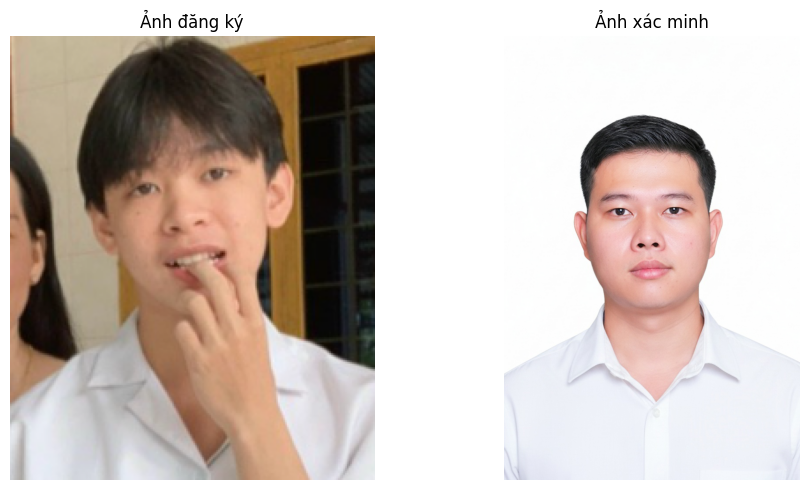


KẾT QUẢ NHẬN DIỆN
Similarity : 0.0485
Threshold  : 0.363
Result     : MISMATCH

Return code: 0


In [37]:
from google.colab import files
from PIL import Image
import matplotlib.pyplot as plt
import subprocess
import json
import shutil
from pathlib import Path

cli_project = "/content/drive/MyDrive/ai/src/CityGym.AI.Cli/CityGym.AI.Cli.csproj"
models = "/content/drive/MyDrive/ai/models"
test_dir = Path("/content/drive/MyDrive/ai/test-data")
test_dir.mkdir(parents=True, exist_ok=True)

threshold = 0.363

print("Upload ẢNH ĐĂNG KÝ")
uploaded = files.upload()

if len(uploaded) != 1:
    raise ValueError("Vui lòng upload đúng 1 ảnh đăng ký.")

enroll_name = next(iter(uploaded))
enroll_source = Path("/content") / enroll_name
enroll_path = test_dir / "current_enroll.jpg"

shutil.copy2(enroll_source, enroll_path)

print()
print("Upload ẢNH XÁC MINH")
uploaded = files.upload()

if len(uploaded) != 1:
    raise ValueError("Vui lòng upload đúng 1 ảnh xác minh.")

probe_name = next(iter(uploaded))
probe_source = Path("/content") / probe_name
probe_path = test_dir / "current_probe.jpg"

shutil.copy2(probe_source, probe_path)

enroll_img = Image.open(enroll_path)
probe_img = Image.open(probe_path)

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].imshow(enroll_img)
axes[0].set_title("Ảnh đăng ký")
axes[0].axis("off")

axes[1].imshow(probe_img)
axes[1].set_title("Ảnh xác minh")
axes[1].axis("off")

plt.tight_layout()
plt.show()

result = subprocess.run(
    [
        "dotnet",
        "run",
        "--project",
        cli_project,
        "--configuration",
        "Release",
        "--no-build",
        "--",
        "compare",
        models,
        str(enroll_path),
        str(probe_path),
        str(threshold)
    ],
    capture_output=True,
    text=True
)

print()

if result.returncode == 0:
    data = json.loads(result.stdout)

    score = float(data["score"])
    found = bool(data["found"])

    print("KẾT QUẢ NHẬN DIỆN")
    print("Similarity :", round(score, 4))
    print("Threshold  :", threshold)
    print("Result     :", "MATCH" if found else "MISMATCH")

else:
    print("KHÔNG THỂ NHẬN DIỆN")

    error_text = result.stderr.strip()

    try:
        error = json.loads(error_text)

        if error.get("code") == "NO_FACE":
            print("Lỗi: Không phát hiện được khuôn mặt trong một trong hai ảnh.")

        elif error.get("code") == "MULTIPLE_FACES":
            print("Lỗi: Phát hiện nhiều hơn một khuôn mặt trong ảnh.")

        else:
            print("Lỗi:", error.get("message", error_text))

    except:
        print(error_text)

print()
print("Return code:", result.returncode)